# ITCS 6169/8169 — Computer Vision
## Assignment 2: Tuning a SigLIP-style CNN (from scratch, self-supervised)

Goal of this notebook: find a good **CNN + SigLIP-style SSL** recipe, cheaply, to compare against the ViT later.
Everything trains from scratch on the provided 2,400 images only (no pretrained weights, no extra data).

**Plan (target: ≲ 2 hours total on your PC)**
1. **Ablations** — change *one* SigLIP/SSL knob at a time from a base config, 50 SSL epochs each, scored by the **frozen-feature linear probe** on validation (no fine-tuning, so each run is only a few minutes).
2. **Combine** — knobs that clearly helped (≥ `MIN_GAIN`) are merged into one config and re-checked against the base.
3. **Final** — full-length SSL pretraining of the chosen config (2 seeds) → fine-tune → validation, then **test once**.
4. *(Optional)* two fine-tuning-recipe variants on the final encoder.

Removed vs. the previous notebook: supervised baseline, CLIP-style loss, joint training.
Set `SMOKE_TEST = True` first to check the whole notebook runs end-to-end in a couple of minutes.

> **128px finals-only mode.** This is the same notebook as the 64px version with `IMG_SIZE = 128`. All ablation / search cells are skipped; the configuration chosen at 64px is loaded from `checkpoints/` and trained at the higher resolution. Results and checkpoints get a `128px_` prefix, so nothing from the 64px runs is overwritten or reused. **Prerequisite:** the 64px notebook must have been run in the same project folder. Restart the kernel and check the GPU is free before starting.

In [1]:
# Core imports
from pathlib import Path
import random, time, copy, math, json, gc, threading, queue

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from PIL import Image

try:
    import torch_directml  # to allow for AMD gpu usage
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"DirectML available: {HAS_DML}")

PyTorch version: 2.4.1+cpu
CUDA available: False
DirectML available: True


In [2]:
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment2
Training data: data\train
Testing data: data\test


In [3]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_device():
    """CUDA if available, else DirectML (AMD GPU on Windows), else CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if HAS_DML:
        return torch_directml.device()
    return torch.device("cpu")

set_random_seed(SEED)
device = get_device()
print('Device:', device)

Device: privateuseone:0


## Config
`BASE_CFG` is the starting point that every ablation modifies (these are the values from your 64px / 100-epoch SigLIP run). `GRID` lists the alternatives tried **one knob at a time**.

In [4]:
SMOKE_TEST = False   # True -> tiny runs, just to check the notebook runs end-to-end
IMG_SIZE = 128           # 64 = the tuned setting; any other size runs in FINALS_ONLY mode
PREFIX = ('smoke_' if SMOKE_TEST else '') + ('' if IMG_SIZE == 64 else f'{IMG_SIZE}px_')   # keeps smoke / other-resolution files separate
FINALS_ONLY = IMG_SIZE != 64   # skip all ablations; reuse the config selected by the 64px notebook
HIRES_SSL_BS = 64        # FINALS_ONLY: SSL batch size (a 128px batch of 128 image pairs may not fit in GPU memory)
HIRES_SSL_EPOCHS = 100   # FINALS_ONLY: SSL epochs (the 64px probe curves plateaued around epoch 100-120)

# Data
BATCH_SIZE = 32          # fine-tuning batch size
VAL_FRACTION = 0.20

# Fine-tuning recipe (same as your A1 final model)
SUP_LR = 5e-4
SUP_WD = 0.05
MIXUP_ALPHA = 0.4
CUTMIX_ALPHA = 1.0
CUTMIX_PROB = 0.5
FT_EPOCHS = 100

FEAT_DIM = 256           # TNet output width (widths[-1])

# ---- SigLIP-style SSL: base config + the knobs we ablate ----
BASE_CFG = dict(
    bs=128,              # contrastive batch size
    lr=1e-3,             # SSL learning rate (AdamW, cosine)
    wd=0.05,
    crop_min=0.3,        # RandomResizedCrop lower scale bound (smaller = harder views)
    jitter=0.4,          # color-jitter strength (brightness/contrast/saturation; hue = jitter/4)
    gray_p=0.2,          # probability of random grayscale
    init_t=10.0,         # SigLIP temperature init   (t = exp(log_t), learnable)
    init_b=-10.0,        # SigLIP bias init          (learnable)
    proj_hidden=512,
    proj_dim=128,
)

GRID = {                 # knob -> alternatives to try (base value is already covered by the 'base' run)
    'bs':       [64, 256],
    'crop_min': [0.15, 0.5],
    'jitter':   [0.2, 0.8],
    'init_t':   [3.0, 30.0],
    'init_b':   [-5.0, -15.0],
    'lr':       [5e-4, 2e-3],
}

# ---- Budget ----
ABL_EPOCHS = 50          # SSL epochs per ablation run (cosine schedule over these 50)
ABL_PROBE_EVERY = 10     # probes at 10,20,...; the score is the mean of the last two probes
MIN_GAIN = 0.02          # a change must beat the base by >= 2 pts of probe acc to be adopted (val noise ~1.5 pts)
MANUAL_OVERRIDE = {}     # e.g. {'bs': 64} to force a knob regardless of the ablation outcome
FORCE_RERUN = False      # False -> finished ablation runs are loaded from the JSON file (resume after a crash)

FINAL_SSL_EPOCHS = 200
FINAL_PROBE_EVERY = 10
FINAL_SEEDS = (0, 1)
RUN_FT_ABLATION = not FINALS_ONLY   # two fine-tuning-recipe variants on the seed-0 final encoder

if SMOKE_TEST:
    ABL_EPOCHS = FINAL_SSL_EPOCHS = FT_EPOCHS = 2
    ABL_PROBE_EVERY = FINAL_PROBE_EVERY = 1
    GRID = dict(list(GRID.items())[:2])
    FINAL_SEEDS = (0,)

IMAGENET_MEAN = [0.485, 0.456, 0.406]   # only used as generic input normalization (no pretrained weights)
IMAGENET_STD = [0.229, 0.224, 0.225]

## Data

In [5]:
# Mixup / CutMix helpers (from A1)
def mixup_data(x, y, alpha=0.2):
    '''Returns mixed inputs, pairs of targets, and lambda.'''
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)

    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def cutmix_data(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_ratio), int(W * cut_ratio)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)

    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (H * W))   # correct lam for the clipped box
    return x, y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def random_grayscale_rgb(img):
    # Augment only on training; validation/test should stay clean.
    if random.random() < 0.5:
        gray = img.convert("L")
        return gray.convert("RGB")
    return img

class Prefetch:
    """Runs a DataLoader in a background thread so augmentation overlaps with GPU compute."""
    def __init__(self, loader, depth=3):
        self.loader, self.depth = loader, depth

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        q = queue.Queue(maxsize=self.depth)
        done = object()
        def work():
            try:
                for item in self.loader:
                    q.put(item)
            except Exception as e:          # hand errors to the main thread instead of hanging it
                q.put(e)
            q.put(done)
        threading.Thread(target=work, daemon=True).start()
        while True:
            item = q.get()
            if item is done:
                return
            if isinstance(item, Exception):
                raise item
            yield item

In [6]:
# Fine-tuning augmentation (from A1) and clean eval preprocessing
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.Lambda(random_grayscale_rgb),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def build_ssl_aug(crop_min=0.3, jitter=0.4, gray_p=0.2):
    """SSL view augmentation; the three arguments are ablation knobs."""
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(crop_min, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomApply([transforms.ColorJitter(jitter, jitter, jitter, jitter / 4)], p=0.8),
        transforms.RandomGrayscale(p=gray_p),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

ssl_aug = build_ssl_aug(BASE_CFG['crop_min'], BASE_CFG['jitter'], BASE_CFG['gray_p'])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

class TwoView(torch.utils.data.Dataset):
    """Two independently augmented views of the same image (the label is returned but never used by SSL)."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        return self.transform(image), self.transform(image), label

In [7]:
base_train_dataset = datasets.ImageFolder(TRAIN_ROOT)
class_names = base_train_dataset.classes
num_classes = len(class_names)

# decode + resize once; the split below uses a seeded generator so it is identical in every run
cached_train = [(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), y) for img, y in base_train_dataset]

val_size = int(round(len(base_train_dataset) * VAL_FRACTION))
train_size = len(base_train_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(cached_train, [train_size, val_size], generator=generator)

train_dataset = TransformSubset(train_subset, train_transform)
val_dataset = TransformSubset(val_subset, eval_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=eval_transform)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

def make_ssl_loader(bs=None, aug=None):
    """Two-view loader over the TRAIN split only (never val/test). drop_last keeps batches full."""
    return Prefetch(DataLoader(TwoView(train_subset, aug or ssl_aug), batch_size=bs or BASE_CFG['bs'],
                               shuffle=True, drop_last=True, num_workers=0, pin_memory=pin))

print(f'Classes ({num_classes}): {class_names}')
print(f'Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')

Classes (16): ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Train: 1920 | Validation: 480 | Test: 400


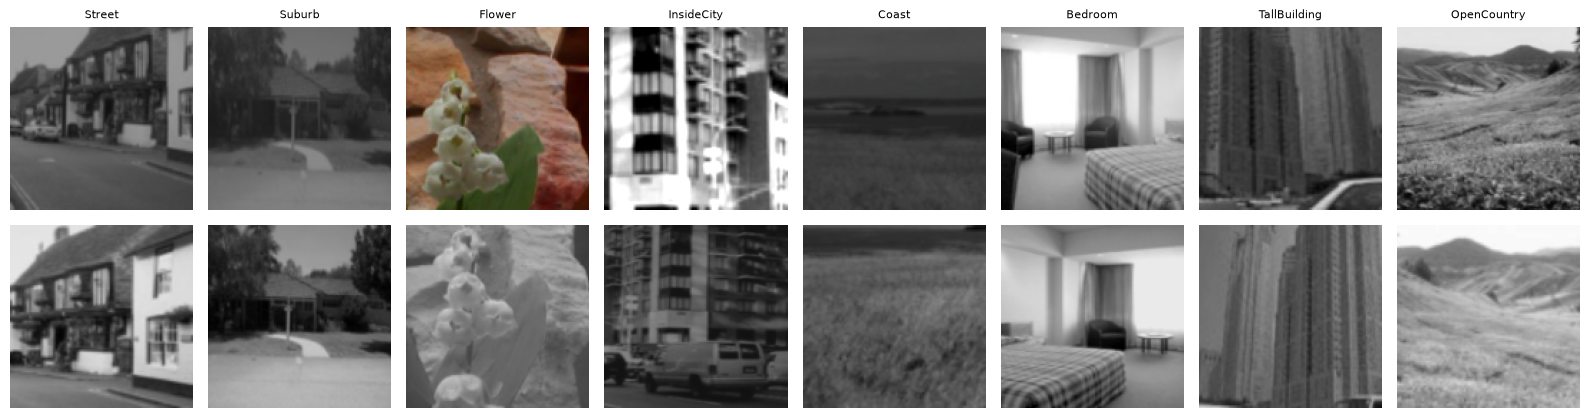

In [8]:
# Sanity check: pairs of SSL views (each column = one image; rows = its two views).
def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

v1, v2, y = next(iter(make_ssl_loader(bs=8)))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    axes[0, i].imshow(denorm(v1[i])); axes[0, i].set_title(class_names[y[i].item()], fontsize=8)
    axes[1, i].imshow(denorm(v2[i]))
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout()
plt.show()

## Models and loss
`SSLNet` = your `TNet` conv stack as encoder + global pool + projection head. `SigLIPStyleLoss` scores every entry of the n×n similarity matrix as an independent binary decision (+1 on the diagonal, −1 elsewhere) with learnable temperature `t` and bias `b`. There are no captions, so this is the SimCLR-style two-view version of SigLIP.

In [9]:
def conv_bn_relu(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )

class TNet(nn.Module):
    def __init__(self, num_classes=16, widths=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = widths
        self.features = nn.Sequential(
            conv_bn_relu(3, c1), conv_bn_relu(c1, c1), nn.MaxPool2d(2),
            conv_bn_relu(c1, c2), conv_bn_relu(c2, c2), nn.MaxPool2d(2),
            conv_bn_relu(c2, c3), conv_bn_relu(c3, c3), nn.MaxPool2d(2),
            conv_bn_relu(c3, c4), conv_bn_relu(c4, c4),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c4, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class SSLNet(nn.Module):
    """Encoder (TNet conv stack) + global pool + projection head."""
    def __init__(self, feat_dim=FEAT_DIM, hidden=BASE_CFG['proj_hidden'], proj_dim=BASE_CFG['proj_dim']):
        super().__init__()
        self.features = TNet(num_classes=num_classes).features
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())
        self.head = nn.Sequential(
            nn.Linear(feat_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, proj_dim),
        )

    def embed(self, x):          # representation used for probing / fine-tuning
        return self.pool(self.features(x))

    def forward(self, x):        # projection used by the SSL loss
        return self.head(self.embed(x))


class SigLIPStyleLoss(nn.Module):
    """Pairwise sigmoid loss: +1 label for matching pairs, -1 for every other pair in the batch."""
    def __init__(self, init_t=10.0, init_b=-10.0):
        super().__init__()
        self.log_t = nn.Parameter(torch.tensor(math.log(init_t)))
        self.b = nn.Parameter(torch.tensor(float(init_b)))

    def forward(self, z1, z2):
        z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
        logits = self.log_t.exp() * (z1 @ z2.T) + self.b
        labels = (2 * torch.eye(len(z1)) - 1).to(z1.device)   # build on CPU: torch.eye is broken on DirectML
        return -F.logsigmoid(labels * logits).sum() / len(z1)


print(f'TNet trainable parameters: {sum(p.numel() for p in TNet(num_classes=num_classes).parameters()):,}')
print(f'SSLNet trainable parameters: {sum(p.numel() for p in SSLNet().parameters()):,}')

TNet trainable parameters: 1,177,328
SSLNet trainable parameters: 1,371,488


## Training utilities

In [10]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    running_loss = 0.0
    criterion = nn.CrossEntropyLoss()
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, scheduler=None, epochs=20, device=device,
                mixup_alpha=0.0, cutmix_alpha=1.0, cutmix_prob=0.0, print_every=1):
    criterion = nn.CrossEntropyLoss()
    model = model.to(device)
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_seen = 0
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            # Pick at most one mixing method per batch
            use_cutmix = cutmix_prob > 0 and np.random.rand() < cutmix_prob
            use_mixup = (not use_cutmix) and mixup_alpha > 0
            if use_cutmix:
                images, labels_a, labels_b, lam = cutmix_data(images, labels, alpha=cutmix_alpha)
            elif use_mixup:
                images, labels_a, labels_b, lam = mixup_data(images, labels, alpha=mixup_alpha)

            logits = model(images)
            if use_cutmix or use_mixup:
                loss = mixup_criterion(criterion, logits, labels_a, labels_b, lam)
            else:
                loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            total_seen += labels.size(0)

        train_loss = total_loss / total_seen
        val_loss, val_acc = evaluate(model, val_loader, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if scheduler is not None:
            scheduler.step()
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        if epoch % print_every == 0 or epoch == epochs:
            print(f'Epoch {epoch:03d}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
                  f'val acc {val_acc:.4f} | {time.time() - start:.1f}s')

    last_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f'Best validation accuracy: {best_val_acc:.4f}')
    return model, history, best_state, last_state


# ---- Linear probe: how good are the frozen features? ----
@torch.no_grad()
def embed_dataset(net, loader):
    net.eval()
    feats, ys = [], []
    for x, y in loader:
        feats.append(net.embed(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(feats), torch.cat(ys)

def linear_probe(net, steps=300, lr=1e-2, wd=1e-4):
    """Linear layer on FROZEN encoder features (train split, no augmentation) -> validation accuracy."""
    train_clean = DataLoader(TransformSubset(train_subset, eval_transform), batch_size=128, shuffle=False)
    ftr, ytr = embed_dataset(net, train_clean)
    fva, yva = embed_dataset(net, val_loader)
    mu, sd = ftr.mean(0), ftr.std(0) + 1e-6
    ftr, fva = (ftr - mu) / sd, (fva - mu) / sd

    clf = nn.Linear(ftr.shape[1], num_classes)
    opt = optim.AdamW(clf.parameters(), lr=lr, weight_decay=wd)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(clf(ftr), ytr).backward()
        opt.step()
    with torch.no_grad():
        return (clf(fva).argmax(1) == yva).float().mean().item()

In [11]:
# ---- Checkpoint helpers ----
CKPT_DIR = PROJECT_ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)

def slug(name):
    """'SigLIP CNN final s0' -> 'siglip_cnn_final_s0'"""
    return ''.join(c.lower() if c.isalnum() else '_' for c in name).strip('_')

def cpu_state(sd):
    """Detached CPU copy of a state dict (safe to keep around and to save)."""
    return {k: v.detach().cpu().clone() for k, v in sd.items()}

def save_ckpt(name, stage, best_state, last_state, **extra):
    """Write checkpoints/<slug>_<stage>.pt (temp file first, so a crash can't corrupt the old one)."""
    path = CKPT_DIR / f'{slug(name)}_{stage}.pt'
    tmp = path.with_suffix('.tmp')
    torch.save({'best_state': best_state, 'last_state': last_state, **extra}, tmp)
    tmp.replace(path)
    return path

def load_ckpt(name, stage, which='best'):
    ck = torch.load(CKPT_DIR / f'{slug(name)}_{stage}.pt', map_location='cpu')
    return ck[f'{which}_state'], ck          # which = 'best' or 'last'

def load_pretrained(name, which='best'):
    """Rebuild a pretrained SSLNet (encoder + projection head) from a checkpoint."""
    sd, ck = load_ckpt(name, 'pretrain', which)
    net = SSLNet(**ck['hparams'].get('net_kwargs', {}))
    net.load_state_dict(sd)
    return net.to(device)

def load_finetuned(name, which='best'):
    """Rebuild a fine-tuned TNet classifier from a checkpoint."""
    sd, _ = load_ckpt(name, 'finetune', which)
    model = TNet(num_classes=num_classes)
    model.load_state_dict(sd)
    return model.to(device)

In [12]:
def ssl_pretrain(loss_fn, bs, epochs, lr, wd, seed=SEED, probe_every=10, aug=None, name='',
                 save=True, print_every=10, net_kwargs=None):
    """SSL pretraining on two-view batches. Labels are never used. Returns (net, log).
    Prints on every probe epoch (and every `print_every` epochs). If save=True and name is given,
    checkpoints/<name>_pretrain.pt is updated at every probe (best-probe + latest weights)."""
    net_kwargs = net_kwargs or {}
    set_random_seed(seed)
    net, loss_fn = SSLNet(**net_kwargs).to(device), loss_fn.to(device)
    loader = make_ssl_loader(bs, aug)

    # loss params (temperature / bias) get no weight decay
    opt = optim.AdamW([{'params': net.parameters(), 'weight_decay': wd},
                       {'params': loss_fn.parameters(), 'weight_decay': 0.0}], lr=lr)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    log = {'loss': [], 'probe_epoch': [], 'probe_acc': []}
    best_probe, best_epoch, best_state = -1.0, 0, None
    hparams = dict(loss=type(loss_fn).__name__, bs=bs, epochs=epochs, lr=lr, wd=wd, seed=seed, net_kwargs=net_kwargs)
    start = time.time()
    for ep in range(1, epochs + 1):
        net.train()
        tot, n = 0.0, 0
        for v1, v2, _ in loader:                         # label ignored
            x = torch.cat([v1, v2]).to(device)           # one forward pass -> consistent BatchNorm stats
            z1, z2 = net(x).chunk(2)
            loss = loss_fn(z1, z2)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item(); n += 1
        sched.step()
        avg = tot / n
        log['loss'].append(avg)

        line = f'[{name}] ep {ep:03d}/{epochs} | ssl loss {avg:.4f}'
        do_probe = (ep % probe_every == 0) or (ep == epochs)
        if do_probe:
            acc = linear_probe(net)
            log['probe_epoch'].append(ep); log['probe_acc'].append(acc)
            if acc > best_probe:
                best_probe, best_epoch, best_state = acc, ep, cpu_state(net.state_dict())
            params = ', '.join(f'{k}={v.item():.2f}' for k, v in loss_fn.named_parameters())
            line += f' | probe val acc {acc:.4f} (best {best_probe:.4f} @ {best_epoch}) | {params}'
            if save and name:
                save_ckpt(name, 'pretrain', best_state, cpu_state(net.state_dict()),
                          loss_state=cpu_state(loss_fn.state_dict()), log=log, hparams=hparams,
                          best_probe_acc=best_probe, best_probe_epoch=best_epoch, last_epoch=ep)
        line += f' | {time.time() - start:.0f}s'
        if do_probe or ep % print_every == 0:
            print(line)

    log['best_probe_acc'], log['best_probe_epoch'] = best_probe, best_epoch
    log['seconds'] = time.time() - start
    return net, log


def run_cfg(cfg, epochs, seed=SEED, probe_every=10, name='', save=False, print_every=10):
    """SigLIP-style SSL pretraining with every knob taken from `cfg`."""
    return ssl_pretrain(
        SigLIPStyleLoss(cfg['init_t'], cfg['init_b']),
        bs=cfg['bs'], epochs=epochs, lr=cfg['lr'], wd=cfg['wd'], seed=seed, probe_every=probe_every,
        aug=build_ssl_aug(cfg['crop_min'], cfg['jitter'], cfg['gray_p']), name=name, save=save,
        print_every=print_every, net_kwargs=dict(hidden=cfg['proj_hidden'], proj_dim=cfg['proj_dim']))


def finetune(net=None, epochs=None, lr=None, enc_lr_mult=1.0, mix=True, print_every=10):
    """net=None -> fresh TNet; otherwise start from net's encoder.
    enc_lr_mult scales the encoder LR relative to the classifier; mix=False turns off mixup/CutMix."""
    epochs, lr = epochs or FT_EPOCHS, lr or SUP_LR
    model = TNet(num_classes=num_classes)
    if net is not None:
        # transfer through CPU clones: loading a DirectML state dict directly leaves requires_grad=False
        model.features.load_state_dict({k: v.detach().cpu().clone() for k, v in net.features.state_dict().items()})
    model = model.to(device)
    assert all(p.requires_grad for p in model.parameters()), 'some parameters are frozen'
    optimizer = optim.AdamW([{'params': model.features.parameters(), 'lr': lr * enc_lr_mult},
                             {'params': model.classifier.parameters(), 'lr': lr}], weight_decay=SUP_WD)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return train_model(model, train_loader, val_loader, optimizer, scheduler=scheduler, epochs=epochs,
                       device=device, mixup_alpha=MIXUP_ALPHA if mix else 0.0, cutmix_alpha=CUTMIX_ALPHA,
                       cutmix_prob=CUTMIX_PROB if mix else 0.0, print_every=print_every)

In [13]:
# Bookkeeping for the final models
results = {}      # name -> dict of validation numbers
models = {}       # name -> trained model (best-val weights), for the test-set evaluation at the end
probe_logs = {}   # name -> SSL pretraining log

def record(name, history, model, probe_acc=None, note=''):
    results[name] = {'val_best': max(history['val_acc']), 'val_last': history['val_acc'][-1],
                     'probe_val': probe_acc, 'note': note}
    models[name] = model
    print(f"Logged '{name}': best val {results[name]['val_best']:.4f}, last val {results[name]['val_last']:.4f}")

## Step 0: Controls
A **randomly initialised, untrained encoder** already gives a linear-probe accuracy well above chance (1/16 ≈ 6%). Every ablation number should be read relative to this floor, not to zero.

In [14]:
set_random_seed(SEED)
rand_probe = linear_probe(SSLNet().to(device))
print(f'Random-init encoder, linear probe val acc: {rand_probe:.4f}   (chance = {1/num_classes:.4f})')

Random-init encoder, linear probe val acc: 0.5396   (chance = 0.0625)


## Step 1: One-knob-at-a-time ablations (linear probe, no fine-tuning)
Each run: `ABL_EPOCHS` SSL epochs → score = mean of the last two linear probes on validation. Results are appended to a JSON file after every run, so if the kernel dies you can re-run this cell and it **resumes** where it stopped.

How to read the table: with 480 validation images one probe has a standard error of ≈1.5 pts, and the `base (seed 1)` row measures run-to-run noise directly. Differences smaller than `MIN_GAIN` (2 pts) are treated as ties and the base value is kept.

In [15]:
if not FINALS_ONLY:
    ABL_FILE = CKPT_DIR / f'{PREFIX}siglip_ablation_{ABL_EPOCHS}ep.json'
    abl = json.loads(ABL_FILE.read_text()) if (ABL_FILE.exists() and not FORCE_RERUN) else {}

    def run_ablation(name, knob, value, cfg, seed=SEED):
        if name in abl:
            print(f'[{name}] already done -> skipping (probe {abl[name]["probe_mean2"]:.4f})')
            return
        t0 = time.time()
        try:
            net, log = run_cfg(cfg, ABL_EPOCHS, seed=seed, probe_every=ABL_PROBE_EVERY, name=name, save=False,
                               print_every=ABL_EPOCHS)
        except RuntimeError as e:                 # e.g. DirectML out-of-memory at a large batch size
            print(f'[{name}] FAILED: {str(e)[:150]}')
            gc.collect()
            return
        abl[name] = dict(knob=knob, value=value, seed=seed, cfg=cfg, epochs=ABL_EPOCHS,
                         probe_final=log['probe_acc'][-1], probe_mean2=float(np.mean(log['probe_acc'][-2:])),
                         probe_curve=log['probe_acc'], probe_epochs=log['probe_epoch'],
                         loss_last=log['loss'][-1], seconds=time.time() - t0)
        ABL_FILE.write_text(json.dumps(abl, indent=1))
        del net
        gc.collect()
        print(f'[{name}] done in {(time.time() - t0) / 60:.1f} min | probe {abl[name]["probe_mean2"]:.4f}\n')

    t_start = time.time()
    run_ablation('base', 'base', None, BASE_CFG)
    run_ablation('base (seed 1)', 'base', None, BASE_CFG, seed=SEED + 1)      # run-to-run noise estimate
    for knob, values in GRID.items():
        for v in values:
            run_ablation(f'{knob}={v}', knob, v, {**BASE_CFG, knob: v})
    print(f'Ablation phase wall time this session: {(time.time() - t_start) / 60:.1f} min')

In [16]:
if not FINALS_ONLY:
    # Ablation table + chart
    base_score = abl['base']['probe_mean2']
    noise = abs(base_score - abl['base (seed 1)']['probe_mean2']) if 'base (seed 1)' in abl else float('nan')
    print(f'Random-init floor: {rand_probe:.4f} | base: {base_score:.4f} | base seed-to-seed gap: {noise:.4f}\n')
    print(f"{'run':<18}{'probe (mean last 2)':>20}{'final probe':>13}{'delta vs base':>15}{'min':>7}")
    for name, r in abl.items():
        d = r['probe_mean2'] - base_score
        flag = '  <-- adopt?' if (r['knob'] != 'base' and d >= MIN_GAIN) else ''
        print(f"{name:<18}{r['probe_mean2']:>20.4f}{r['probe_final']:>13.4f}{d:>+15.4f}{r['seconds']/60:>7.1f}{flag}")

    knobs = [k for k in GRID if any(abl.get(f'{k}={v}') for v in GRID[k])]
    if knobs:
        fig, axes = plt.subplots(1, len(knobs), figsize=(2.6 * len(knobs), 3.4), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, k in zip(axes, knobs):
            pts = [(v, abl[f'{k}={v}']['probe_mean2']) for v in GRID[k] if f'{k}={v}' in abl]
            pts.append((BASE_CFG[k], base_score))
            pts.sort(key=lambda p: p[0])
            ax.plot([str(p[0]) for p in pts], [p[1] for p in pts], marker='o')
            ax.axhspan(base_score - MIN_GAIN, base_score + MIN_GAIN, color='gray', alpha=0.2)
            ax.axhline(rand_probe, color='red', ls=':', lw=1)
            ax.set_title(k); ax.tick_params(axis='x', labelsize=8)
        axes[0].set_ylabel('probe val acc')
        plt.suptitle('Gray band = base +/- MIN_GAIN (treated as a tie); red dotted = random-init encoder', fontsize=9)
        plt.tight_layout(); plt.show()

## Step 2: Combine the knobs that helped
Per knob, take the best alternative only if it beats the base by ≥ `MIN_GAIN`. The combination was never run before, and knobs interact (e.g. batch size and temperature), so it is **re-run and only kept if it is at least as good as the base**. Use `MANUAL_OVERRIDE` in the config cell to force a value instead.

In [17]:
if not FINALS_ONLY:
    chosen = {}
    for knob, values in GRID.items():
        cands = [(abl[f'{knob}={v}']['probe_mean2'], v) for v in values if f'{knob}={v}' in abl]
        if cands:
            best_score, best_v = max(cands)
            if best_score - base_score >= MIN_GAIN:
                chosen[knob] = best_v
    chosen.update(MANUAL_OVERRIDE)
    print('Knobs adopted:', chosen if chosen else 'none (base config kept)')

    COMBINED_CFG = {**BASE_CFG, **chosen}
    if chosen:
        run_ablation('combined', 'combined', str(chosen), COMBINED_CFG)
        comb = abl.get('combined')
        if comb is not None and comb['probe_mean2'] >= base_score:
            FINAL_CFG = COMBINED_CFG
            print(f"Combined ({comb['probe_mean2']:.4f}) >= base ({base_score:.4f}) -> using the combined config")
        else:
            FINAL_CFG = dict(BASE_CFG)
            print('Combined config did not beat the base -> falling back to the base config')
    else:
        FINAL_CFG = dict(BASE_CFG)

    (CKPT_DIR / f'{PREFIX}siglip_final_cfg.json').write_text(json.dumps(FINAL_CFG, indent=1))
    print('FINAL_CFG:', FINAL_CFG)

    sec_per_ep = abl['base']['seconds'] / ABL_EPOCHS
    print(f'\nMeasured ~{sec_per_ep:.1f}s per SSL epoch (incl. probes) -> final SSL pretraining '
          f'~{sec_per_ep * FINAL_SSL_EPOCHS / 60:.0f} min per seed, {len(FINAL_SEEDS)} seed(s).')
else:
    _p = 'smoke_' if (SMOKE_TEST and (CKPT_DIR / 'smoke_siglip_final_cfg.json').exists()) else ''
    FINAL_CFG = json.loads((CKPT_DIR / f'{_p}siglip_final_cfg.json').read_text())     # selected by the 64px ablations
    FINAL_CFG['bs'] = HIRES_SSL_BS
    if not SMOKE_TEST:
        FINAL_SSL_EPOCHS = HIRES_SSL_EPOCHS
    RUN_FT_ABLATION = False
    (CKPT_DIR / f'{PREFIX}siglip_final_cfg.json').write_text(json.dumps(FINAL_CFG, indent=1))
    print('FINALS_ONLY: using the 64px config at', IMG_SIZE, 'px ->', FINAL_CFG, '| SSL epochs:', FINAL_SSL_EPOCHS)

FINALS_ONLY: using the 64px config at 128 px -> {'bs': 64, 'lr': 0.0005, 'wd': 0.05, 'crop_min': 0.3, 'jitter': 0.4, 'gray_p': 0.2, 'init_t': 10.0, 'init_b': -15.0, 'proj_hidden': 512, 'proj_dim': 128} | SSL epochs: 100


## Step 3: Final runs
Full-length SSL pretraining with `FINAL_CFG` (`FINAL_SSL_EPOCHS` epochs, cosine schedule) → fine-tune with the A1 recipe (`FT_EPOCHS`). Checkpoints are written to `checkpoints/` (best-probe and latest weights for pretraining; best-val and last weights for fine-tuning). Seeds change initialisation and augmentation randomness; the train/val split stays fixed.

In [18]:
def run_final(seed):
    name = f'{PREFIX}SigLIP CNN final s{seed}'
    net, log = run_cfg(FINAL_CFG, FINAL_SSL_EPOCHS, seed=seed, probe_every=FINAL_PROBE_EVERY, name=name,
                       save=True, print_every=FINAL_PROBE_EVERY)
    probe_logs[name] = log
    print(f"Pretraining done in {log['seconds'] / 60:.1f} min | best probe {log['best_probe_acc']:.4f} "
          f"@ epoch {log['best_probe_epoch']} | final probe {log['probe_acc'][-1]:.4f}\n")
    set_random_seed(seed)
    model, hist, ft_best, ft_last = finetune(net)
    save_ckpt(name, 'finetune', cpu_state(ft_best), cpu_state(ft_last), history=hist,
              hparams=dict(epochs=FT_EPOCHS, lr=SUP_LR, wd=SUP_WD, mixup_alpha=MIXUP_ALPHA,
                           cutmix_alpha=CUTMIX_ALPHA, cutmix_prob=CUTMIX_PROB, seed=seed, cfg=FINAL_CFG))
    record(name, hist, model, probe_acc=log['probe_acc'][-1], note=f'seed {seed}')
    return net, model, hist

final_nets = {}
final_hists = {}
for s in FINAL_SEEDS:
    t0 = time.time()
    final_nets[s], _, final_hists[s] = run_final(s)
    print(f'--- seed {s} total: {(time.time() - t0) / 60:.1f} min ---\n')

C:\Users\Bryan\AppData\Local\Temp\ipykernel_22384\681562559.py:60: UserWarning: The operator 'aten::log_sigmoid_forward' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  return -F.logsigmoid(labels * logits).sum() / len(z1)


[128px_SigLIP CNN final s0] ep 010/100 | ssl loss 4.1146 | probe val acc 0.5979 (best 0.5979 @ 10) | log_t=2.45, b=-14.86 | 125s
[128px_SigLIP CNN final s0] ep 020/100 | ssl loss 2.6565 | probe val acc 0.6771 (best 0.6771 @ 20) | log_t=2.60, b=-14.73 | 240s
[128px_SigLIP CNN final s0] ep 030/100 | ssl loss 1.6648 | probe val acc 0.7354 (best 0.7354 @ 30) | log_t=2.71, b=-14.63 | 356s
[128px_SigLIP CNN final s0] ep 040/100 | ssl loss 1.1846 | probe val acc 0.7188 (best 0.7354 @ 30) | log_t=2.78, b=-14.57 | 483s
[128px_SigLIP CNN final s0] ep 050/100 | ssl loss 0.8877 | probe val acc 0.7688 (best 0.7688 @ 50) | log_t=2.83, b=-14.54 | 609s
[128px_SigLIP CNN final s0] ep 060/100 | ssl loss 0.6839 | probe val acc 0.7500 (best 0.7688 @ 50) | log_t=2.85, b=-14.52 | 735s
[128px_SigLIP CNN final s0] ep 070/100 | ssl loss 0.6361 | probe val acc 0.7479 (best 0.7688 @ 50) | log_t=2.87, b=-14.50 | 861s
[128px_SigLIP CNN final s0] ep 080/100 | ssl loss 0.5348 | probe val acc 0.7688 (best 0.7688 @ 50

## Step 4 (optional): Fine-tuning recipe on the final encoder
Two cheap checks on the seed-0 pretrained encoder, same epochs as the default recipe so they are directly comparable: (a) a **lower encoder LR** (×0.3) so fine-tuning does not wash out the pretrained features, and (b) **no mixup/CutMix**. Set `RUN_FT_ABLATION = False` to skip (saves ~2 fine-tunes).

In [19]:
if RUN_FT_ABLATION:
    s0 = FINAL_SEEDS[0]
    for label, kw in [('enc lr x0.3', dict(enc_lr_mult=0.3)), ('no mixup/cutmix', dict(mix=False))]:
        print(f'\n=== fine-tune variant: {label} ===')
        set_random_seed(s0)
        m, h, _, _ = finetune(final_nets[s0], **kw)
        record(f'{PREFIX}SigLIP CNN s{s0} ft: {label}', h, m, probe_acc=probe_logs[f'{PREFIX}SigLIP CNN final s{s0}']['probe_acc'][-1],
               note=f'fine-tune variant ({label})')

## Results (validation)

Experiment                                    val best  val last  probe val   note
128px_SigLIP CNN final s0                       0.8938    0.8896     0.7792   seed 0
128px_SigLIP CNN final s1                       0.8896    0.8812     0.7771   seed 1

Final seeds: val best mean 0.8917 (min 0.8896, max 0.8938)


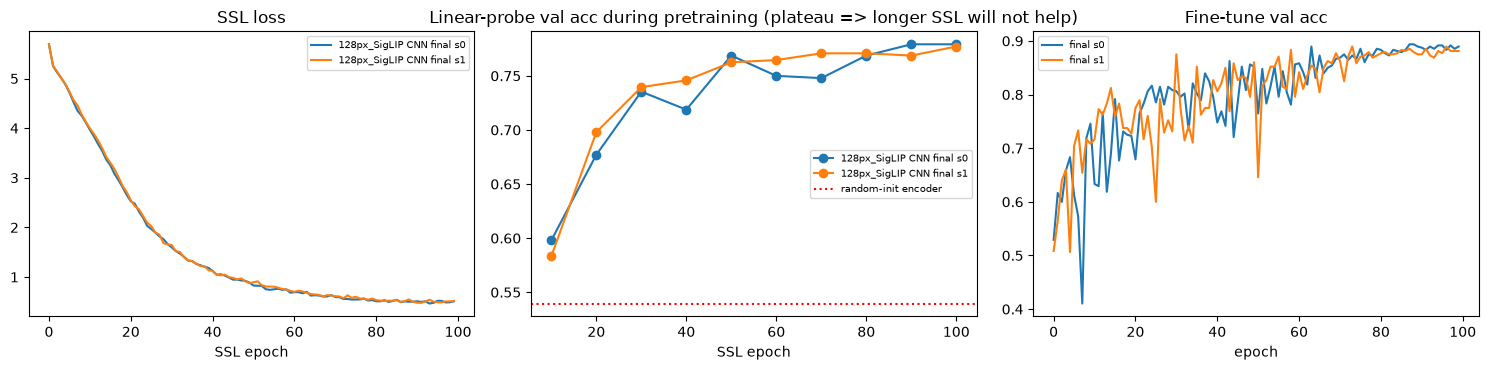

In [20]:
print(f"{'Experiment':<44}{'val best':>10}{'val last':>10}{'probe val':>11}   note")
for name, r in results.items():
    probe = f"{r['probe_val']:.4f}" if r['probe_val'] is not None else '   -'
    print(f"{name:<44}{r['val_best']:>10.4f}{r['val_last']:>10.4f}{probe:>11}   {r['note']}")

finals = [n for n in results if n.startswith(f'{PREFIX}SigLIP CNN final')]
if len(finals) > 1:
    vb = np.array([results[n]['val_best'] for n in finals])
    print(f'\nFinal seeds: val best mean {vb.mean():.4f} (min {vb.min():.4f}, max {vb.max():.4f})')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name, log in probe_logs.items():
    ax[0].plot(log['loss'], label=name)
    ax[1].plot(log['probe_epoch'], log['probe_acc'], marker='o', label=name)
ax[1].axhline(rand_probe, color='red', ls=':', label='random-init encoder')
ax[0].set_title('SSL loss'); ax[0].set_xlabel('SSL epoch')
ax[1].set_title('Linear-probe val acc during pretraining (plateau => longer SSL will not help)'); ax[1].set_xlabel('SSL epoch')
for s, h in final_hists.items():
    ax[2].plot(h['val_acc'], label=f'final s{s}')
ax[2].set_title('Fine-tune val acc'); ax[2].set_xlabel('epoch')
for a in ax: a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Experiment log (fill this in)
Use **test** accuracy for the final report table; use validation for decisions.

| Experiment | What changed? | Why did you try it? | Probe / val acc | Test acc | What did you learn? |
|---|---|---|---|---|---|
| Random-init encoder probe | Nothing trained | Floor | | | |
| SigLIP CNN base (50 ep) | Nothing | Ablation reference | | | |
| bs 64 / 256 | | | | | |
| crop_min 0.15 / 0.5 | | | | | |
| jitter 0.2 / 0.8 | | | | | |
| init_t 3 / 30 | | | | | |
| init_b -5 / -15 | | | | | |
| lr 5e-4 / 2e-3 | | | | | |
| Combined | | | | | |
| Final (200 ep SSL + FT) | | | | | |

## Final test-set evaluation
**Run once**, after all decisions are made on validation. Only the final seeds are evaluated (not the fine-tune variants — add a name to `FINALISTS` if you adopt one).

In [21]:
FINALISTS = [n for n in models if n.startswith(f'{PREFIX}SigLIP CNN final')]
test_accs = []
print(f"{'Model':<36}{'test loss':>11}{'test acc':>10}")
for name in FINALISTS:
    tl, ta = evaluate(models[name], test_loader, device)
    test_accs.append(ta)
    print(f'{name:<36}{tl:>11.4f}{ta:>10.4f}')
if len(test_accs) > 1:
    print(f'\nmean {np.mean(test_accs):.4f} | std {np.std(test_accs):.4f} over {len(test_accs)} seeds')

Model                                 test loss  test acc
128px_SigLIP CNN final s0                0.5510    0.8750
128px_SigLIP CNN final s1                0.5932    0.8625

mean 0.8688 | std 0.0062 over 2 seeds


Validation (SigLIP CNN, seed 0) overall accuracy: 0.8938

Class             Acc     N   Most confused with
LivingRoom      0.731    26   Bedroom
Store           0.742    31   InsideCity
Industrial      0.759    29   InsideCity
InsideCity      0.767    30   Store
OpenCountry     0.786    28   Coast
Kitchen         0.833    30   LivingRoom
Bedroom         0.872    39   LivingRoom
Highway         0.929    28   Coast
Office          0.958    24   Bedroom
Mountain        0.964    28   Industrial
Flower          0.968    31   Mountain
Street          0.969    32   Highway
Coast           1.000    33   -
Forest          1.000    29   -
Suburb          1.000    34   -
TallBuilding    1.000    28   -


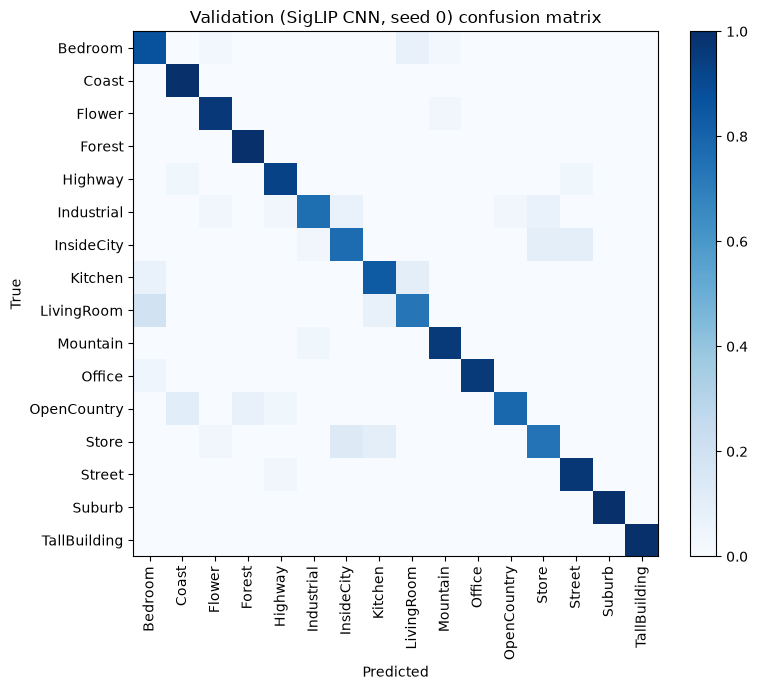

In [22]:
# Per-class analysis (from A1). Validation for decisions; switch to test_loader only for the final report.
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def per_class_report(model, loader, class_names, device, title=''):
    preds, labels = get_predictions(model, loader, device)
    n = len(class_names)
    cm = np.zeros((n, n), dtype=int)           # rows = true class, cols = predicted class
    for t, p in zip(labels, preds):
        cm[t, p] += 1
    support = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / np.maximum(support, 1)

    print(f'{title} overall accuracy: {(preds == labels).mean():.4f}\n')
    print(f'{"Class":<14}{"Acc":>7}{"N":>6}   Most confused with')
    for i in np.argsort(per_class_acc):        # worst classes first
        off = cm[i].copy(); off[i] = 0
        confused = class_names[off.argmax()] if off.sum() > 0 else '-'
        print(f'{class_names[i]:<14}{per_class_acc[i]:>7.3f}{support[i]:>6}   {confused}')

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm / np.maximum(support[:, None], 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{title} confusion matrix')
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
    return cm, per_class_acc

cm_val, acc_val = per_class_report(models[FINALISTS[0]], val_loader, class_names, device, 'Validation (SigLIP CNN, seed 0)')

## Ideas if time remains
- **Architecture/head:** `proj_dim` / `proj_hidden` (kept at 128/512 here), a wider or ResNet-style encoder.
- **Longer SSL:** if the final probe curve is still rising at epoch 200, try 400.
- **Interactions:** re-test the knob that mattered most (usually batch size or crop scale) at the final length.
- **Next:** drop `FINAL_CFG` + the saved checkpoint into the ViT comparison; the same split, 64px cache and probe/fine-tune protocol apply.